# Practice 1 — Bước 2: Huấn luyện CNN trên Fashion-MNIST

Ở notebook này ta sẽ:
1. Tạo DataLoader (train 90% / validation 10%, augmentation cho tập train).
2. Xây dựng mô hình CNN `FashionCNN` (~0.87 triệu tham số).
3. Huấn luyện với CrossEntropyLoss + AdamW + ReduceLROnPlateau + **early stopping 5**.
4. Vẽ đường cong học tập **mỗi epoch** và lưu trọng số tốt nhất vào `models/best_model.pth`.

> **Cấu hình mở rộng:** tối đa **30 epoch** (`config.NUM_EPOCHS_EXTENDED`), early stopping **patience = 5** (`config.EARLY_STOP_PATIENCE_EXTENDED`).
> Tài liệu liên quan: [`docs/training.md`](../docs/training.md) · [`docs/model.md`](../docs/model.md).

## 0. Chuẩn bị

In [2]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from src import config, data, utils
from src.model import build_model
from src.trainer import Trainer

utils.set_seed(config.SEED)
device = utils.get_device()
print('Thiết bị huấn luyện:', device)

Thiết bị huấn luyện: cuda


## 1. Tạo DataLoader

- Tập train gốc 60.000 ảnh được chia: **54.000 train / 6.000 validation**.
- Tập train được áp augmentation: **lật ngang ngẫu nhiên + xoay ±10°** — giúp mô hình
  khái quát hoá tốt hơn, tránh học thuộc nét ảnh.
- Validation/test **không** augmentation, không shuffle để đánh giá khách quan.

> Chi tiết pipeline dữ liệu: [`docs/data.md`](../docs/data.md).

In [3]:
train_loader, val_loader, test_loader = data.get_dataloaders(
    batch_size=config.BATCH_SIZE,
    val_split=config.VAL_SPLIT,
    use_augmentation=True,
)

print(f'Số batch: train={len(train_loader)}, val={len(val_loader)}, test={len(test_loader)}')

[data] Nạp từ CSV:
  - train: fashion-mnist_train.csv
  - test : fashion-mnist_test.csv
[data] Số ảnh: train=54000, val=6000, test=10000 (batch_size=64, augmentation=bật)
Số batch: train=844, val=47, test=79


## 2. Xây dựng mô hình

Kiến trúc `FashionCNN` (định nghĩa trong `src/model.py`):

| Khối | Các lớp | Kích thước vào → ra |
|---|---|---|
| Conv 1 | Conv3×3 ×2 + BN + ReLU + MaxPool + Dropout | (1, 28, 28) → (32, 14, 14) |
| Conv 2 | Conv3×3 ×2 + BN + ReLU + MaxPool + Dropout | (32, 14, 14) → (64, 7, 7) |
| MLP | Flatten → Linear(3136→256) + BN + ReLU + Dropout → Linear(256→10) | 3136 → 256 → 10 |

> Chi tiết kiến trúc: [`docs/model.md`](../docs/model.md).

In [4]:
model = build_model(num_classes=config.NUM_CLASSES)
print(model)
print(f'\nTổng số tham số có thể học: {utils.count_parameters(model):,}')

FashionCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout2d(p=0.25, inplace=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (12): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (13): ReLU(inplace=True)
    (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=

## 3. Huấn luyện (30 epoch + early stopping 5)

Cấu hình:
- **Loss:** `CrossEntropyLoss` (đa lớp, đã gộp softmax).
- **Optimizer:** `AdamW` (lr=1e-3, weight_decay=1e-4).
- **Scheduler:** `ReduceLROnPlateau` — giảm một nửa lr nếu val_loss đứng sau 2 epoch.
- **Early stopping:** dừng nếu val_loss không cải thiện sau **5 epoch** (`config.EARLY_STOP_PATIENCE_EXTENDED`).
- **Epoch tối đa:** **30** (`config.NUM_EPOCHS_EXTENDED`).
- **Checkpoint:** mỗi lần val_loss đạt mức tốt mới thì lưu đè vào `models/best_model.pth`.

⏱️ Trên CPU mỗi epoch khoảng 2–5 phút; trên GPU chỉ vài chục giây.

> Ghi chú chi tiết: [`docs/training.md`](../docs/training.md).

In [5]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=config.LEARNING_RATE,
    weight_decay=config.WEIGHT_DECAY,
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=2
)

trainer = Trainer(model, criterion, optimizer, scheduler, device)
history = trainer.fit(
    train_loader,
    val_loader,
    epochs=config.NUM_EPOCHS_EXTENDED,             # 30 epoch tối đa
    patience=config.EARLY_STOP_PATIENCE_EXTENDED,  # early stopping = 5
    save_path=config.BEST_MODEL_PATH,
)

Epoch 1/30 [train]:   0%|          | 0/844 [00:00<?, ?it/s]

Epoch 001/30 | train loss 0.5193, acc 0.8151 | val loss 0.2926, acc 0.8945 | 26.5s
  -> Lưu model tốt nhất (val_loss=0.2926)


Epoch 2/30 [train]:   0%|          | 0/844 [00:00<?, ?it/s]

Epoch 002/30 | train loss 0.3701, acc 0.8674 | val loss 0.2577, acc 0.9048 | 20.0s
  -> Lưu model tốt nhất (val_loss=0.2577)


Epoch 3/30 [train]:   0%|          | 0/844 [00:00<?, ?it/s]

Epoch 003/30 | train loss 0.3272, acc 0.8815 | val loss 0.2434, acc 0.9098 | 15.1s
  -> Lưu model tốt nhất (val_loss=0.2434)


... (50 outputs left out)

Epoch 29/30 [train]:   0%|          | 0/844 [00:00<?, ?it/s]

Epoch 029/30 | train loss 0.1873, acc 0.9311 | val loss 0.1652, acc 0.9422 | 13.5s


Epoch 30/30 [train]:   0%|          | 0/844 [00:00<?, ?it/s]

Epoch 030/30 | train loss 0.1833, acc 0.9333 | val loss 0.1652, acc 0.9437 | 13.5s


## 4. Đường cong học tập (vẽ mỗi epoch)

- Nếu **train loss giảm mà val loss tăng** → mô hình bị overfitting
  (đã được giảm nhẹ nhờ Dropout + weight decay + augmentation).
- Nếu cả hai cùng giảm và còn cao → có thể tăng epoch hoặc learning rate.
- Đồ thị được vẽ **mỗi epoch** (`config.PLOT_EPOCH_STEP = 1`) và lưu vào
  `outputs/figures/02_training_history.png`.

> Diễn giải kết quả: [`docs/training.md`](../docs/training.md).

[utils] Đã lưu hình: C:\Users\Admin\Downloads\Practice_11\outputs\figures\02_training_history.png


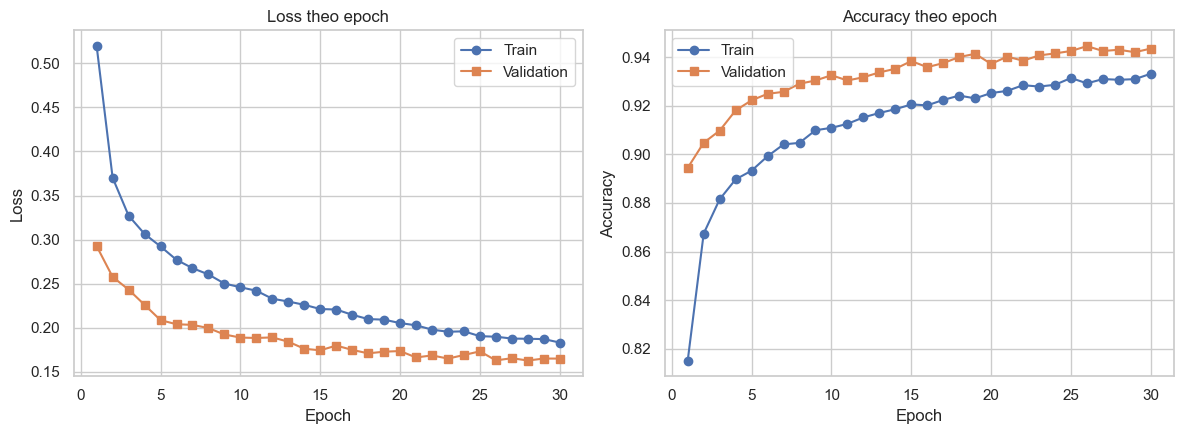

[utils] Đã lưu bảng: C:\Users\Admin\Downloads\Practice_11\outputs\tables\02_training_history.csv
Model tốt nhất lưu tại: C:\Users\Admin\Downloads\Practice_11\models\best_model.pth


In [6]:
fig = utils.plot_training_history(history, save_name='02_training_history')
plt.show()

# Lưu bảng loss/accuracy từng epoch ra outputs/tables/
utils.save_table(pd.DataFrame(history), '02_training_history')
print('Model tốt nhất lưu tại:', config.BEST_MODEL_PATH)

## 5. Ghi chú sau huấn luyện

Sau khi chạy xong, ghi lại kết quả ở đây (ví dụ):

- Epoch tốt nhất: **...** — val_loss **...**, val_acc **...**
- Early stopping kích hoạt ở epoch: **...** (hoặc chạy hết 30 epoch nếu val_loss vẫn giảm)
- Nhận xét về đường cong học tập: ...

➡️ **Bước tiếp theo:** mở `03_evaluation_and_inference.ipynb` để đánh giá chi tiết
trên tập test và suy luận ảnh đơn lẻ. Tài liệu tương ứng: [`docs/evaluation.md`](../docs/evaluation.md) · [`docs/demo.md`](../docs/demo.md).

In [ ]:
import pandas as pd
from IPython.display import display

# Đọc file CSV
df = pd.read_csv('outputs/tables/02_training_history.csv')

# Hiển thị dữ liệu dưới dạng bảng
display(df)